# 2. Several issues: scoring the packages

**Examples of:**

- a negotiation on **several issues** at once: an agreement is a **package**;
- how each agent scores a package with its own (private) **scoring sheet**;
- the Pareto frontier and the Nash package;
- an issue where the two agents are **not opposed**;
- why "splitting the difference on each issue" wastes value, and how **trading** issues (logrolling) helps both.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from charging import *

## 2.1 Three issues

Alice and Bob now negotiate three issues: the margin, the number of charges per month and the time slot.

**The margin.** The kWh does not cost Alice the same at every hour: 0.20 EUR during the day and the evening,
0.16 EUR at night (off-peak hours). So Bob pays **Alice's tariff of the slot plus a margin** (`ALICE_TARIFF`):
Alice passes her cost on, and the agents negotiate the **margin** (her profit per kWh).
For instance, a margin of 0.10 EUR/kWh in the day slot means a price of 0.30 EUR/kWh (`price_paid(package)`).

| Issue | Options | Alice (owner) | Bob (user) |
|---|---|---|---|
| margin (EUR/kWh) | 0.00, 0.02, ..., 0.14 | high | low |
| charges per month | 4, 6, 8, 10, 12 | few (Bob comes into her yard) | many (he needs about 8, more is comfortable) |
| time slot | 7h-18h, 18h-22h, 22h-7h | the day (she is at work), not the evening | the day (between two visits), not the evening |

**The time slots.**
- **7h-18h**: Alice is at work, so Bob does not disturb her; Bob comes home between two visits,
and with 22 kW one hour is enough for about 22 kWh.
- **18h-22h**: the evening is the worst slot for Alice: back from work, she prefer to plug her car a little. Bob could plug in when he comes back, but he prefers the day.
- **22h-7h**: Alice accepts the night, but she fears the noise (Bob coming into the yard); Bob must go out to plug in, but the kWh is cheaper for him (off-peak tariff).

A **package** is a possible agreement: the complete terms under which Bob would use Alice's wallbox, with one option for each issue.   
It is written as a dict: `{"margin": 0.08, "charges": 8, "slot": "22h-7h"}` means *"Bob pays Alice's night tariff plus 0.08 EUR/kWh (i.e. 0.24 EUR/kWh), and can charge 8 times a month, between 22h and 7h"*.  
If the agents agree on a package, it becomes their deal; otherwise there is no deal.

Each agent has a **private scoring sheet**: the points it gives to each option (`ALICE_SHEET`, `BOB_SHEET`).  
The agents will only know their own.

| | Alice's points | Bob's points |
|---|---|---|
| margin 0.00 / 0.04 / 0.08 / 0.14 | 0 / 8 / 17 / 30 | 30 / 22 / 14 / 0 |
| charges 4 / 8 / 12 | 20 / 12 / 0 | 0 / 15 / 25 |
| slot 7h-18h / 18h-22h / 22h-7h | 25 / 0 / 10 | 15 / 6 / 12 |
| maximum | 75 | 70 |
| **reservation** (below: no deal) | **30** | **25** |

(see `charging.py` for all the options)

In [2]:
print("Alice's sheet:", {issue: ALICE_SHEET[issue] for issue in ISSUES_3})
print("Bob's sheet:  ", {issue: BOB_SHEET[issue] for issue in ISSUES_3})

Alice's sheet: {'margin': {0.0: 0, 0.02: 4, 0.04: 8, 0.06: 12, 0.08: 17, 0.1: 22, 0.12: 26, 0.14: 30}, 'charges': {4: 20, 6: 17, 8: 12, 10: 6, 12: 0}, 'slot': {'7h-18h': 25, '18h-22h': 0, '22h-7h': 10}}
Bob's sheet:   {'margin': {0.0: 30, 0.02: 26, 0.04: 22, 0.06: 18, 0.08: 14, 0.1: 9, 0.12: 5, 0.14: 0}, 'charges': {4: 0, 6: 7, 8: 15, 10: 21, 12: 25}, 'slot': {'7h-18h': 15, '18h-22h': 6, '22h-7h': 12}}


---

**Exercise 1**.
- Write a function `my_score(package, sheet)` that adds the points of each issue of the package.
- Check it on the package `{"margin": 0.08, "charges": 8, "slot": "22h-7h"}`: what are the scores of Alice and Bob?  
Is the package acceptable for both? Which price does Bob pay?

In [3]:
# Exercise 1: your code here
#offered !
def my_score(package, sheet):
    total = 0
    for issue, option in package.items():
        total += sheet[issue][option]
    return total

In [5]:
#let's test it
sample_proposal = {"margin": 0.08, "charges": 8, "slot": "22h-7h"}
print(f"proposal: {sample_proposal}, price paid by Bob: {price_paid(sample_proposal)} EUR/kWh")
alice_score = my_score(sample_proposal, ALICE_SHEET)
bob_score = my_score(sample_proposal, BOB_SHEET)
print(f"Alice: score={alice_score}, minimum points to accept={ALICE_RESERVATION_3}")
print(f"Bob: score={bob_score}, minimum points to accept={BOB_RESERVATION_3}")


proposal: {'margin': 0.08, 'charges': 8, 'slot': '22h-7h'}, price paid by Bob: 0.24 EUR/kWh
Alice: score=39, minimum points to accept=30
Bob: score=41, minimum points to accept=25


> **Reading.**
> - Alice 39 (≥ 30), Bob 41 (≥ 25): acceptable for both. Bob pays 0.16 + 0.08 = 0.24 EUR/kWh.
> - This package **splits the difference** everywhere: the middle margin, the middle number of charges,
> and the night slot, the second choice of both agents.  
> *(N.B. in fact, `charging.py` contains the same function, named `score`)*.

---

## 2.2 All the possible packages

**Exercise 2**.
- `all_packages(ISSUES_3)` returns the list of all the packages, possible point of agreements.   
How many are there?
- How many are acceptable for **both** agents (score ≥ reservation)?
- Draw them with `show_packages(packages, ALICE_RESERVATION_3, BOB_RESERVATION_3)`.

In [ ]:
# Exercise 2: your code here
#TODO

120 packages, 63 acceptable for both


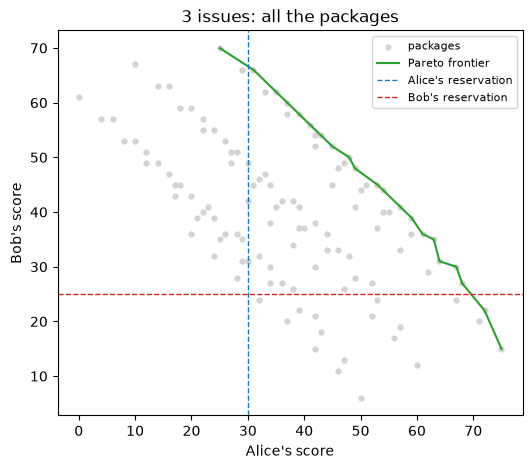

In [10]:

show_packages(packages, ALICE_RESERVATION_3, BOB_RESERVATION_3, title="3 issues: all the packages");

> **Reading.** 
> - 120 packages ($8 \times 5 \times 3$), 63 of them acceptable for both: the top-right corner of the figure.
> - The green line is the **Pareto frontier**: from these packages, no change can help one agent without hurting the other.

---

**Exercise 3**.
- Write a function `is_dominated(p, packages)`: is there a package at least as good for both, and strictly better for one?
- List the Pareto-optimal packages with their scores (you can check with `pareto(packages)`).
- What do they have in common?

In [ ]:
# Exercise 3: your code here

In [11]:
def is_dominated(p, packages):
#TODO

front = [p for p in packages if not is_dominated(p, packages)]
for p in sorted(front, key=lambda p: score(p, ALICE_SHEET)):
    print(score(p, ALICE_SHEET), score(p, BOB_SHEET), p)


25 70 {'margin': 0.0, 'charges': 12, 'slot': '7h-18h'}
31 66 {'margin': 0.0, 'charges': 10, 'slot': '7h-18h'}
35 62 {'margin': 0.02, 'charges': 10, 'slot': '7h-18h'}
37 60 {'margin': 0.0, 'charges': 8, 'slot': '7h-18h'}
39 58 {'margin': 0.04, 'charges': 10, 'slot': '7h-18h'}
41 56 {'margin': 0.02, 'charges': 8, 'slot': '7h-18h'}
43 54 {'margin': 0.06, 'charges': 10, 'slot': '7h-18h'}
45 52 {'margin': 0.04, 'charges': 8, 'slot': '7h-18h'}
48 50 {'margin': 0.08, 'charges': 10, 'slot': '7h-18h'}
49 48 {'margin': 0.06, 'charges': 8, 'slot': '7h-18h'}
53 45 {'margin': 0.1, 'charges': 10, 'slot': '7h-18h'}
54 44 {'margin': 0.08, 'charges': 8, 'slot': '7h-18h'}
57 41 {'margin': 0.12, 'charges': 10, 'slot': '7h-18h'}
59 39 {'margin': 0.1, 'charges': 8, 'slot': '7h-18h'}
61 36 {'margin': 0.14, 'charges': 10, 'slot': '7h-18h'}
63 35 {'margin': 0.12, 'charges': 8, 'slot': '7h-18h'}
64 31 {'margin': 0.1, 'charges': 6, 'slot': '7h-18h'}
67 30 {'margin': 0.14, 'charges': 8, 'slot': '7h-18h'}
68 27 {

-> to write by the student 
> **Reading.**
> - **All** the Pareto-optimal packages use the **day slot 7h-18h**.
> - Both agents prefer the day to the night, and the night to the evening: on the slot their interests are **not opposed**.  
> Choosing the day is a "free" agreement: it helps both, and nobody has to give anything in exchange.
> - On the frontier, only the margin and the number of charges change: these two issues are **opposed**.  

-> end to write by the student 



---

## 2.3 The Nash package

**Exercise 4**.
- Among the acceptable packages, find the **Nash package**: it maximises the product of the gains over the reservations,
$(s_A - 30)(s_B - 25)$.
- Compare it with the "split the difference" package of exercise 1 (`sample_proposal`).  
Mark both on the figure (argument `marked` of `show_packages`).

In [ ]:
# Exercise 4: your code here



Nash package: {'margin': 0.1, 'charges': 10, 'slot': '7h-18h'} scores 53 45 | price 0.3
split the difference: {'margin': 0.08, 'charges': 8, 'slot': '22h-7h'} scores 39 41


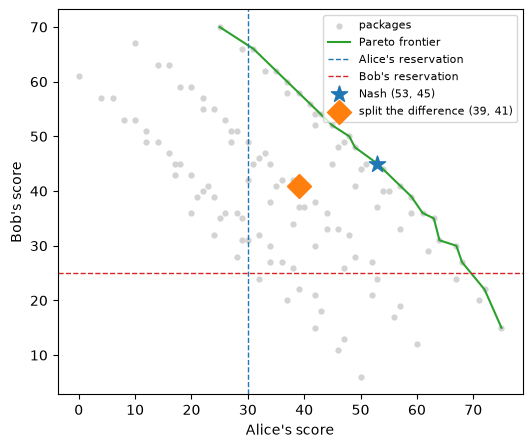

In [ ]:
print("Nash package:", nash, "scores", score(nash, ALICE_SHEET), score(nash, BOB_SHEET), "| price", price_paid(nash))
print("split the difference:", sample_proposal, "scores", score(sample_proposal, ALICE_SHEET), score(sample_proposal, BOB_SHEET))
#to draw the figure : nash is the package that correspond to the nash agreement, sample_proposal is the package taht uses middle values
show_packages(packages, ALICE_RESERVATION_3, BOB_RESERVATION_3, marked={"Nash": nash, "split the difference": sample_proposal});

> **Reading.**
> - Nash package: **margin 0.10 EUR/kWh (price 0.30), 10 charges per month, day slot**: scores (53, 45).
> - Splitting the difference gives (39, 41): **both** agents lose compared with the Nash package.
> - The Nash package does not split each issue:
>   - on the slot, both get their **best** option (the day), instead of a "compromise" (the night) that suits nobody best;
>   - Bob gets **more charges** (what matters most to him), Alice gets a **higher margin** in exchange.
> This is **logrolling**: trading the issues according to their importance for each agent.

---

## Key points

| Idea | In the charger sharing |
|---|---|
| package | one option per issue: margin over Alice's tariff, charges per month, slot |
| scoring sheet | private points of each agent; reservation 30 (Alice), 25 (Bob) |
| compatible issue | both prefer the day slot (then the night, then the evening) |
| opposed issues | margin, charges |
| splitting the difference | (39, 41): dominated |
| Nash package | margin 0.10 (0.30 EUR/kWh), 10 charges, 7h-18h: (53, 45) |